# ¿Más semillas en el Deep Ensemble?

**Pregunta.** El Deep Ensemble promedia 5 SEED entrenados con semillas distintas (42, 1, 2, 3 y 4). ¿Mejoraría con más semillas?

**Cómo se responde sin entrenar.** El `test_predictions.npz` del Deep Ensemble guarda la probabilidad de cada miembro. Para cada tamaño (1 a 5) se promedian **todos los subconjuntos** posibles de semillas de ese tamaño (5, 10, 10, 5 y 1), se aplica el postprocesado y la F1 originales, y se promedian los subconjuntos. Después se ajusta la curva **F1(M) = a − b / M**: la parte que se reduce al promediar M modelos cae como 1/M, y *a* es el techo con infinitas semillas. 15 folds de test. Código: `src/eeg_uq/ensemble_size.py`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidates if (p / 'configs' / 'default.yaml').exists()), Path.cwd())
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))
from eeg_uq import ensemble_size as ens
from eeg_uq import report

pd.set_option('display.width', 250)


def show(figure):
    display(figure)
    plt.close(figure)

REFRESH = False  # True recalcula desde los NPZ (~1 minuto)
sizes = ens.run_all(refresh=REFRESH)

## 1. F1 según el número de miembros

In [2]:
curve = sizes.groupby('miembros')[['F1 (%)', 'precisión (%)', 'recall (%)', 'FP', 'FN', 'desv. F1 entre subconjuntos']].mean()
curve['ganancia de F1 vs anterior'] = curve['F1 (%)'].diff()
display(curve.round(2))
print('Por evaluación:')
display(report.by_evaluation(sizes.pivot_table(index=['evaluación', 'fold'], columns='miembros', values='F1 (%)')
                             .rename(columns=lambda m: f'{m} miembros').reset_index()))

,F1 (%),precisión (%),recall (%),FP,FN,desv. F1 entre subconjuntos,ganancia de F1 vs anterior
miembros,,,,,,,
1,82.89,83.76,82.39,175.27,188.00,0.57,NaN
2,83.35,84.14,82.83,170.29,183.33,0.38,0.46
3,83.49,84.29,82.95,168.37,182.06,0.30,0.15
4,83.55,84.36,82.98,167.35,181.75,0.24,0.06
5,83.57,84.38,82.98,166.87,181.80,NaN,0.01


Por evaluación:


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
miembros,,,,
1 miembros,82.91 ± 1,82.88 ± 0.57,82.88 ± 1.1,82.89 ± 0.87
2 miembros,83.4 ± 0.99,83.45 ± 0.44,83.19 ± 1.2,83.35 ± 0.86
3 miembros,83.5 ± 0.98,83.68 ± 0.49,83.31 ± 1.1,83.49 ± 0.85
4 miembros,83.54 ± 0.99,83.74 ± 0.43,83.37 ± 1.1,83.55 ± 0.85
5 miembros,83.55 ± 0.91,83.79 ± 0.41,83.35 ± 1.2,83.57 ± 0.85


## 2. Extrapolación a más semillas

Puntos: F1 medido (barras = desviación entre folds). Línea: ajuste F1(M) = a − b/M. La línea punteada es el techo *a*.

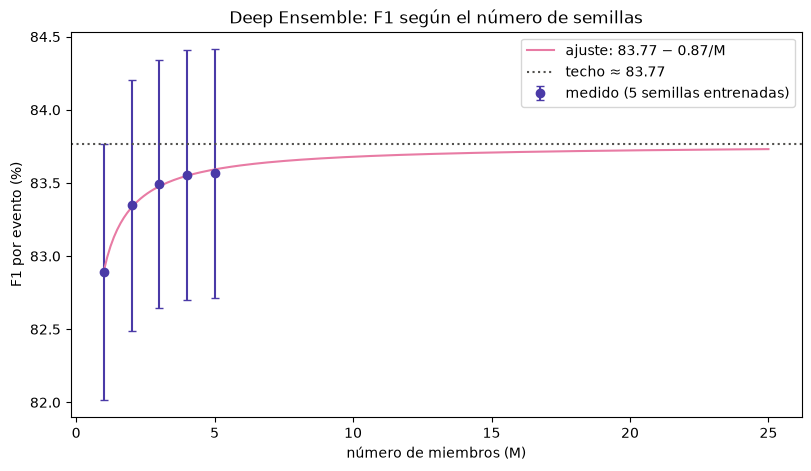

,F1 esperado (%)
M=10,83.68
M=20,83.72
M=50,83.75
límite,83.77


In [3]:
fit = ens.extrapolate(sizes, sizes=(10, 20, 50))
measured = sizes.groupby('miembros')['F1 (%)'].agg(['mean', 'std'])
m = np.linspace(1, 25, 200)
fig, ax = plt.subplots(figsize=(8, 4.6), constrained_layout=True)
ax.errorbar(measured.index, measured['mean'], yerr=measured['std'], fmt='o', color='#4a3aa7', capsize=3, label='medido (5 semillas entrenadas)')
ax.plot(m, fit['a'] - fit['b'] / m, color='#e87ba4', label=f"ajuste: {fit['a']:.2f} − {fit['b']:.2f}/M")
ax.axhline(fit['a'], color=report.CHANCE, linestyle=':', label=f"techo ≈ {fit['a']:.2f}")
ax.set_xlabel('número de miembros (M)')
ax.set_ylabel('F1 por evento (%)')
ax.set_title('Deep Ensemble: F1 según el número de semillas')
ax.legend()
show(fig)
display(pd.Series({k: v for k, v in fit.items() if k.startswith('M=') or k == 'límite'}, name='F1 esperado (%)').round(2).to_frame())

## Hallazgos

1. **Promediar semillas ayuda, pero con ganancias decrecientes.** Un SEED solo da 82.89 (promedio de las 5 semillas). Dos miembros suben +0.46, el tercero +0.14, el cuarto +0.06 y el quinto +0.02.
2. **El Deep Ensemble actual ya está cerca de su techo.** El ajuste F1(M) ≈ 83.77 − 0.87/M predice ~83.68 con 10 semillas, ~83.72 con 20 y un máximo de ~83.77 con infinitas, apenas +0.2 sobre el actual (83.57).
3. **Por qué se aplana.** Promediar solo corrige los errores en que las semillas **no están de acuerdo**. Todas comparten arquitectura y datos, así que comparten muchos errores, y esos no se van al promediar: por ejemplo, la mitad de los FN tiene probabilidad < 0.25 en los cinco miembros.
4. **Qué semillas se usan importa poco.** La desviación de F1 entre subconjuntos del mismo tamaño baja de 0.57 (1 miembro) a 0.24 (4 miembros).

**Conclusión.** Entrenar más semillas iguales no vale la pena: duplicar el costo daría ~+0.1 de F1, dentro del ruido entre folds. Si se invierte en entrenar, conviene buscar **diversidad** (otra arquitectura, otra augmentación, subconjuntos distintos de sujetos) para que los miembros se equivoquen en lugares distintos.